<a href="https://colab.research.google.com/github/Pulakspbl/Machine-learning-in-Python-with-scikit-learn/blob/main/Logistic_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [52]:
from sklearn import datasets
dir(datasets)

['__all__',
 '__builtins__',
 '__cached__',
 '__doc__',
 '__file__',
 '__getattr__',
 '__loader__',
 '__name__',
 '__package__',
 '__path__',
 '__spec__',
 '_arff_parser',
 '_base',
 '_california_housing',
 '_covtype',
 '_kddcup99',
 '_lfw',
 '_olivetti_faces',
 '_openml',
 '_rcv1',
 '_samples_generator',
 '_species_distributions',
 '_svmlight_format_fast',
 '_svmlight_format_io',
 '_twenty_newsgroups',
 'clear_data_home',
 'data',
 'descr',
 'dump_svmlight_file',
 'fetch_20newsgroups',
 'fetch_20newsgroups_vectorized',
 'fetch_california_housing',
 'fetch_covtype',
 'fetch_file',
 'fetch_kddcup99',
 'fetch_lfw_pairs',
 'fetch_lfw_people',
 'fetch_olivetti_faces',
 'fetch_openml',
 'fetch_rcv1',
 'fetch_species_distributions',
 'get_data_home',
 'load_breast_cancer',
 'load_diabetes',
 'load_digits',
 'load_files',
 'load_iris',
 'load_linnerud',
 'load_sample_image',
 'load_sample_images',
 'load_svmlight_file',
 'load_svmlight_files',
 'load_wine',
 'make_biclusters',
 'make_blobs',


In [53]:
data = datasets.load_digits(n_class=2, as_frame=True)

In [54]:
X = data.data
y = data.target

In [55]:
y.head()

,target
0,0
1,1
2,0
3,1
4,0


In [59]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import mean_squared_error
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2, stratify=y)


In [75]:
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train,y_train)
y_pred = baseline.predict(X_test)
score = (accuracy_score(y_test,y_pred))
print(score)

0.5


In [69]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
print(classification_report(y_test,y_pred))
confusion_matrix(y_test,y_pred)

              precision    recall  f1-score   support

           0       0.00      0.00      0.00        36
           1       0.50      1.00      0.67        36

    accuracy                           0.50        72
   macro avg       0.25      0.50      0.33        72
weighted avg       0.25      0.50      0.33        72



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


array([[ 0, 36],
       [ 0, 36]])

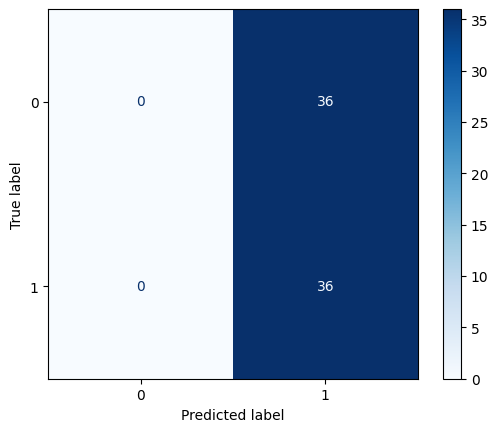

In [77]:
cm = confusion_matrix(y_test,y_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=baseline.classes_
)

disp.plot(cmap='Blues')
plt.show()

In [80]:
model_logistic = LogisticRegression()
model_logistic.fit(X_train,y_train)
y_pred = model_logistic.predict(X_test)
score = (accuracy_score(y_test,y_pred))
tr_accuracy = model_logistic.score(X_train,y_train)
print(score)
print(tr_accuracy)

1.0
1.0


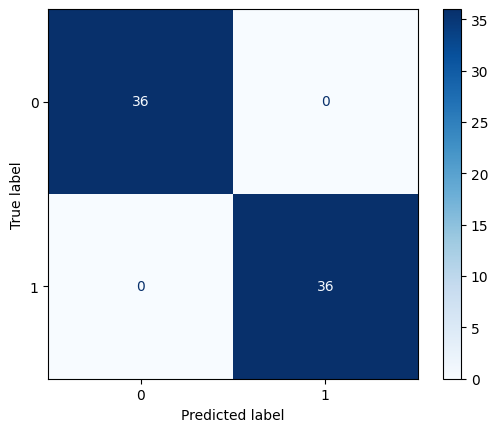

In [79]:
cm_l = confusion_matrix(y_test,y_pred)
disp_l = ConfusionMatrixDisplay(
    confusion_matrix=cm_l,
    display_labels=model_logistic.classes_
)

disp_l.plot(cmap='Blues')
plt.show()

In [87]:
# import metrics
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)

In [88]:
# Calculate metrics
metrics = {
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1 Score': f1_score(y_test, y_pred),
    'ROC-AUC': roc_auc_score(y_test, y_prob)
}

In [90]:
# Predicted probabilities for positive class (1)
y_prob = model_logistic.predict_proba(X_test)[:, 1]

In [91]:
evaluation_df = pd.DataFrame(
    list(metrics.items()),
    columns=['Evaluation Metric', 'Score']
)

print(evaluation_df)

  Evaluation Metric  Score
0          Accuracy    1.0
1         Precision    1.0
2            Recall    1.0
3          F1 Score    1.0
4           ROC-AUC    1.0
